# Notebook 4: Balancing a ball on a round board, with noisy movements
##### *BONUS Lecture/Practical: coordination in 3D with independent SARSA learners*

#### **The board task**
We have a **round board** with a ball on it, held on the left and the right side (think of two people carrying a tray). Each side can do two things:
* **move its side up or down** (low, middle, high). This tilts the board left/right, so the ball rolls left/right.
* **rotate its handle** (backward, neutral, forward). This tilts the board forward/backward, so the ball rolls forward/backward.

How the two sides combine:
* **Height**: what matters is the *difference*. If both sides go up, the board just moves up and nothing happens to the ball. To tilt the board, the sides have to move in **anti-phase**.
* **Rotation**: what matters is the *sum*. If both sides rotate the same way, the tilts add up. If they rotate in opposite directions, they cancel out. To tilt the board forward, the sides have to move **in phase**.

So the same pair of agents has to coordinate in anti-phase for one movement and in phase for the other.

#### **Noisy movements**
The agents' movements are **noisy**: when a side wants to go "high", it ends up a bit higher or lower than it wanted (overshoot and undershoot). The noise has two parts:
* a small **base noise** that is always there (your hands are never perfectly still, even when you do nothing)
* a part that **grows with the size of the movement** (*signal-dependent noise*): a big movement is less precise than a small one. This is a well-known property of human movement (Harris & Wolpert, 1998).

So big movements have come with a higher cost as they make the ball less predictable.

If the ball rolls off the edge of the board, the episode is over. An episode lasts at most 300 steps (so that they get to practice random start locations too).

#### **Independent learning with SARSA**
Each side has its own learner (independent learning): its own Q-table with its own 9 actions (3 heights x 3 rotations). The learners does not see each other's choices, only the state of the ball. They learn with SARSA, like in notebooks 2 and 3.

#### **Reward**
Every step the ball is on the board, the agents get a reward that is higher when the ball is closer to the center: $0.1 \times (1 - \text{distance to center})$. Falling off costs -1. The reward is shared, which means that rewards are the same for each agent.

#### **What does an agent see?**
The position of the ball (x and y) and its velocity (in x and y), each cut into **7 bins**. That is 7 x 7 x 7 x 7 = 2,401 states (more detail than before, so the agents can be more precise, but also more to learn). This is already huge state space. Consider we have 3 (up-down states) x 3 states (tilt states), so the q(s,a) table would have 21609 values to explore for a single agent (and we have two!)...

So remember we have the following components:
* Motor noise: base noise and signal-dependent noise
* Learning rate $\alpha$, discount $\gamma$, exploration $\epsilon$
* Number of training steps

# Lets get started

In [9]:
import mesa
from mesa.agent import AgentSet
from mesa.visualization import SolaraViz
import solara
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
from collections import deque

HEIGHTS = [-1, 0, 1]     # low, middle, high, we keep it managable this way
ROTATIONS = [-1, 0, 1]   # backward, neutral, forward, we keep it manegable this way
HAND_ACTIONS = list(itertools.product(HEIGHTS, ROTATIONS))  # the 9 things one side can do: (height, rotation)
print(f"All possible actions: {HAND_ACTIONS}") # all combinations of actions

All possible actions: [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 0), (0, 1), (1, -1), (1, 0), (1, 1)]


# Agent setup: the ball (simple physics, no wind)

In [10]:
class Ball(mesa.Agent):
    """A ball rolling on a round board with radius 1. It rolls towards the lower side.
    roll_speed: how strongly a tilt accelerates the ball

    The ball is not a learning agent. It has no goals, it just follows simple physics.
    We keep track of two things:
      - position (x, y): where the ball is on the board. (0, 0) is the center.
        x runs from left (-1) to right (+1) (responsive to up-down movements), y from back (-1) to front (+1) (responsive to rotate movements).
      - velocity (vx, vy): how far the ball moves per step, in x and in y.
    The edge of the board is at distance 1 from the center. Beyond that, the ball falls off.
    """
    def __init__(self, model, roll_speed=0.003):
        super().__init__(model)
        self.roll_speed = roll_speed   # bigger = the ball reacts more strongly to a tilt
        self.reset()                   # give the ball a starting position and velocity

    def reset(self):
        """Put the ball at a random place not too far from the center, standing still.
        This is called at the start of every episode."""
        # pick a random direction (an angle between 0 and 360 degrees, in radians)...
        angle = self.model.random.uniform(0, 2 * np.pi)
        # ...and a random distance from the center (at most halfway to the edge)
        distance = self.model.random.uniform(0, 0.5)
        # convert direction + distance into x and y coordinates
        self.x, self.y = distance * np.cos(angle), distance * np.sin(angle)
        # the ball starts standing still
        self.vx, self.vy = 0.0, 0.0

    def step(self):
        """Move the ball one time step, based on how the board is tilted right now."""
        # we use the ACTUAL heights and rotations (agents actions combined + motor noise),
        h, r = self.model.actual_height, self.model.actual_rotation

        # left/right tilt comes from the HEIGHTS of the two sides.
        tilt_x = h["right"] - h["left"]       # positive = right side higher

        # forward/backward tilt comes from the ROTATIONS of the two handles.
        # here the sum matters: same direction adds up, opposite directions cancel out
        tilt_y = r["left"] + r["right"]       # positive = front side higher

        # a tilt accelerates the ball towards the lower side.
        # the minus sign does that: if the right side is higher (tilt_x > 0),
        # the velocity in x goes down, so the ball starts rolling to the left
        self.vx += -self.roll_speed * tilt_x
        self.vy += -self.roll_speed * tilt_y

        # the ball moves by its velocity. Note that the velocity is kept from step to step:
        # the ball has momentum, so it keeps rolling even when the board is level again.
        # that is what makes balancing hard: you have to act before the ball gets too fast
        # we dont have friction, so its a spherical cow approach
        self.x += self.vx
        self.y += self.vy

    def distance(self):
        """Distance from the center of the board."""
        return np.sqrt(self.x ** 2 + self.y ** 2)

    def fallen(self):
        """The board has radius 1, so beyond distance 1 the ball has rolled off the edge."""
        return self.distance() > 1

# Agent setup: the board handler (SARSA)
A handler holds one side of the board (`sides=["left"]`). It can also hold both sides (`sides=["left", "right"]`, then it has 9 x 9 = 81 joint actions: that would be central learning, see the experiments). For every side it holds, it picks a height and a rotation.

The handler only decides what it **wants** to do. The model then adds the motor noise.

In [11]:
class BoardHandler(mesa.Agent):
    """A SARSA learner that holds one (or both) sides of the board.
    sides: which sides this agent controls, e.g. ["left"], or ["left", "right"] if you have technically one agent (central learning)
    alpha: learning rate (how far we move a Q-value when we learn something new)
    gamma: discount (how much we care about rewards further in the future)
    epsilon: exploration (how often we pick a random action instead of the best one)

    When we have one agent per side, each agent is the "brain" for one side of the board.
    The agent only decides what it WANTS (a height and a rotation for its side). The model then
    adds motor noise to get what ACTUALLY happens, and the ball reacts to that.
    """
    def __init__(self, model, sides, alpha=0.1, gamma=0.99, epsilon=0.1):
        super().__init__(model)
        self.sides = sides

        # The list of actions. Each entry is ONE action in the RL sense: the agent picks exactly one per step.
        # With one side, an action is one (height, rotation) pair: 9 actions.
        # With two sides (repeat=2), an action is a pair for the left AND a pair for the right,
        # together counted as ONE action: 9 x 9 = 81 actions.
        self.actions = list(itertools.product(HAND_ACTIONS, repeat=len(sides)))

        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.learning = True    # set to False to "freeze" a trained agent (it still acts, but stops updating)

        # The Q-table: a dictionary from state to an array with one value per action.
        # Q[s][a] = how much reward we expect in the long run if we do action a in state s
        # (and then keep behaving as we do now). It starts empty and fills up as we meet new states.
        self.Q = {}

        # SARSA always needs to know the current state s AND the action a it is going to do there.
        # Both are filled in at the first step of every episode.
        self.state = None       # the state s we were in when we chose our action
        self.action = None      # the action a we chose in s (an index into self.actions)

    def observe(self):
        """The state: bins for the ball's x, y, x-velocity and y-velocity (7 bins each).

        The ball's position and velocity are continuous numbers, but a Q-table needs a limited
        number of states. So we cut each number into bins: np.digitize tells us in which bin
        a number falls (0 to 6). The state is the combination of 4 bin numbers,
        e.g. (3, 3, 4, 2) = "near the center, moving slowly right and slowly backward".
        7 x 7 x 7 x 7 = 2,401 possible states.

        Note: this always looks at the ball as it is RIGHT NOW. Called before the ball rolls,
        it gives s; called after the ball rolled (in learn), it gives s'.
        """
        b = self.model.ball
        # bin edges for the position: narrow near the center (where precision matters most),
        # wider near the edge. 6 edges make 7 bins; the middle bin is "near the center" (-0.12 to 0.12)
        # Note: This is a bit arbitrary, but the bins prevent a huge State space.
        # The agent can only learn to balance the ball if it sees enough examples of each state,
        # so we need a limited number of states.
        position_bins = [-0.6, -0.35, -0.12, 0.12, 0.35, 0.6]
        # bin edges for the velocity: the middle bin is "(almost) standing still"
        velocity_bins = [-0.03, -0.012, -0.004, 0.004, 0.012, 0.03]
        return (int(np.digitize(b.x, position_bins)), int(np.digitize(b.y, position_bins)),
                int(np.digitize(b.vx, velocity_bins)), int(np.digitize(b.vy, velocity_bins)))

    def q_values(self, state):
        """Look up the Q-values of a state.
        A state we have never seen before gets a new row of zeros: we expect nothing yet."""
        if state not in self.Q:
            self.Q[state] = np.zeros(len(self.actions))
        return self.Q[state]

    def choose(self, state):
        """Epsilon-greedy: usually the best action so far, sometimes a random one."""
        # explore: with probability epsilon, pick any action at random
        if self.model.random.random() < self.epsilon:
            return self.model.random.randrange(len(self.actions))
        # exploit: pick the action with the highest Q-value.
        # np.flatnonzero(q == q.max()) gives ALL actions that share the highest value;
        # we pick one of those at random, so ties (e.g. all zeros in a new state) are broken fairly
        q = self.q_values(state) # this gets the values for all actions in this state, creating a new row of zeros if needed
        # in the return statement we take the maximum value, and find all actions that have that value. Then we pick one of those at random.
        return self.model.random.choice(np.flatnonzero(q == q.max()).tolist())

    def act(self):
        """Set the height and rotation we WANT for our side(s)."""
        # at the start of an episode we have no state or action yet, so we pick them now.
        # later in the episode, the action was already chosen at the end of the previous
        # step (in learn()), because SARSA needs to know its next action in advance
        if self.state is None:
            self.state = self.observe() # observe the current state (ball position and velocity)
            self.action = self.choose(self.state) # act based on that state and the current Q-table (policy: epsilon-greedy)
        # unpack our action: one (height, rotation) pair for every side we hold,
        # and write them into the model. The model adds the motor noise later
        for side, (height, rotation) in zip(self.sides, self.actions[self.action]):
            self.model.wanted_height[side] = height
            self.model.wanted_rotation[side] = rotation

    def learn(self, reward, fallen):
        """The SARSA update, using S, A, R, S', A'.
        reward: the shared reward of this step (R)
        fallen: True if the ball fell off. Then there is no future, so the target is just the reward.

        When this runs, the ball has already rolled, which makes it so that self.state is not the state we were in:
          self.state, self.action = s and a: where we WERE and what we DID (before the ball rolled)
          next_state, next_action = s' and a': where we ARE now and what we WILL do next
        We update Q(s, a), the step we just took, using the real reward plus our own
        estimate Q(s', a') for the rest of the future (this is called bootstrapping).
        """
        # S': where is the ball now, after it rolled?
        next_state = self.observe()
        # A': what will we do next? We really will do this action in the next step.
        # That is what makes SARSA "on-policy": it learns about the behaviour it actually follows,
        # including the random exploration moves
        next_action = self.choose(next_state) # this is the action we will take in the next step, based on the new state S' and the current Q-table (policy: epsilon-greedy)

        if self.learning: # only update the Q-table if we are still learning (not frozen)
            q = self.q_values(self.state) # the Q-values of s: the state BEFORE the ball rolled (not the current one!)
            # the target: what we now think Q(s, a) should be
            if fallen:
                target = reward                         # the ball is gone: no future rewards
            else:
                # the reward we just got + the discounted value of what we will do next
                target = reward + self.gamma * self.q_values(next_state)[next_action]
            # TD error = target - what we expected before.
            # we move our estimate a small step (alpha) towards the target
            q[self.action] += self.alpha * (target - q[self.action])

        # The update is done. Now we slide one step forward: s' and a' become the new s and a.
        # In the next model step, act() does action a' (no need to observe again, nothing has moved).
        # Think of a sliding window over the chain s0, a0, r1, s1, a1, r2, s2, ...:
        # every step we update the first pair in the window, then shift the window by one.
        self.state, self.action = next_state, next_action

# Model setup
One model step is:
1. the handlers decide what they **want** (height and rotation for their side)
2. the model adds **motor noise** to get what **actually** happens
3. the ball rolls according to the actual tilt
4. the handlers get the shared reward and do their SARSA update

An episode can end in two ways:
* **The ball falls off.** This is a real end: there is no future anymore. So in the last update the target is just the reward (-1), without anything after it. The agent learns that what happend led to disaster.
* **300 steps survived.** We count it as a success and start a new episode. But this is *our arbitrary* choice, to give the agents a fresh start to practice different starting conditions. For the board nothing has really ended: the ball is still on, and rewards would just keep coming. So in the last update the agents still include the future, like in any normal step: reward + $\gamma$ Q(s', a').

The datacollector collects every step (the batch runner needs that), and the `episode_log` has one row per episode for the learning curves.

To see how the two sides coordinate, we keep the last 5,000 steps of what each side **wanted**, and where the ball was heading (position + 10 x velocity, so where it will be soon).

In [12]:
# Which learners control which sides of the board.
# Each inner list is ONE learner (one brain, one Q-table), and it holds the sides listed in it.
SETUPS = {
    "independent": [["left"], ["right"]],     # two learners, one per side (this notebook)
    "central":     [["left", "right"]],       # one learner for both sides (see the experiments)
}

class BoardModel(mesa.Model):
    """The board model: one ball, and one or two learners holding the sides of the board.

    setup: "independent" (one learner per side) or "central" (one learner for both sides)
    base_noise: motor noise that is always there, even when a side does nothing
    signal_noise: extra motor noise per unit of movement (bigger movements are less precise)
    roll_speed: how strongly a tilt accelerates the ball
    max_steps: maximum length of an episode (reaching it counts as a success)
    alpha, gamma, epsilon: the learning parameters, passed on to every learner
    """
    def __init__(self, setup="independent", base_noise=0.1, signal_noise=0.3, roll_speed=0.003,
                 max_steps=300, alpha=0.1, gamma=0.99, epsilon=0.1, rng=None):
        super().__init__(rng=rng)
        self.setup = setup
        self.max_steps = max_steps
        self.base_noise = base_noise        # noise that is always there
        self.signal_noise = signal_noise    # extra noise per unit of movement (signal-dependent)

        # What the learners WANT for each side (set by the learners in act()).
        # These are the discrete choices: -1, 0 or 1.
        self.wanted_height = {"left": 0, "right": 0}
        self.wanted_rotation = {"left": 0, "right": 0}
        # What ACTUALLY happens (wanted + motor noise, computed by the model in step()).
        # These are continuous numbers, e.g. 1.13 when "high" overshoots a bit.
        # The ball only reacts to these.
        self.actual_height = {"left": 0.0, "right": 0.0}
        self.actual_rotation = {"left": 0.0, "right": 0.0}

        self.ball = Ball(self, roll_speed=roll_speed) # The model gets a Ball agent that rolls on the board. It is not a learning agent, it just follows simple physics.
        self.handlers = AgentSet(
            [BoardHandler(self, sides, alpha=alpha, gamma=gamma, epsilon=epsilon) for sides in SETUPS[setup]],
            random=self.random) # we give the model a set of BoardHandler agents, one per side (or one for both sides if central learning)

        # bookkeeping
        self.t = 0                            # step within the current episode
        self.episode = 0                      # number of finished episodes
        self.recent = deque(maxlen=200)       # lengths of the last 200 episodes, deque is a double-ended queue that automatically discards old entries when it reaches its maximum length
        self.history = deque(maxlen=5000)     # last 5,000 steps: what the sides wanted + where the ball was heading
        self.recent_balance_time = 0          # average length of the last 200 episodes (how long the ball stayed on the board)
        self.recent_success_rate = 0          # average success rate of the last 200 episodes (how often the ball stayed on the board for the full max_steps)
        self.neutral_share = 0                # share of the last 5,000 steps that a side wanted neutral (0)
        self.episode_log = []                 # one row per episode, for the learning curves
        # We also want to know, at the end of each episode, whether the two sides coordinate their intentions:
        # height: expected NEGATIVE correlation (anti-phase), rotation: expected POSITIVE correlation (in phase)
        # (np.nan = "not known yet", until the first episode is finished)
        self.coord_height = np.nan
        self.coord_rotation = np.nan

        # Data collection!
        # The datacollector runs every step (the batch runner of our Mesa version needs that).
        # So it only READS attributes that are computed elsewhere (once per episode),
        # because computing things here, every step, would make training very slow.
        self.datacollector = mesa.DataCollector(
            model_reporters={
                "episode": "episode",
                "recent_balance_time": "recent_balance_time",
                "recent_success_rate": "recent_success_rate",
                "neutral_share": "neutral_share",
                "coord_height": "coord_height",
                "coord_rotation": "coord_rotation",
            }
        )

    def noisy(self, wanted):
        """Motor noise: what actually happens = what we wanted + noise.
        The noise has a base part and a part that grows with the size of the movement.
        Example (base_noise=0.1, signal_noise=0.3):
          wanted 0 (neutral) -> sd = 0.1, so the actual value is usually between -0.2 and 0.2
          wanted 1 (high)    -> sd = 0.4, so the actual value is usually between  0.2 and 1.8
        """
        sd = self.base_noise + self.signal_noise * abs(wanted)   # bigger movement = bigger spread
        return wanted + self.rng.normal(0, sd)                    # draw from a normal distribution around what we wanted

    def coordination(self):
        """Do the two sides coordinate their INTENTIONS? (correlations over the last 5,000 steps)

        height:   the tilt is the DIFFERENCE (right - left), so to tilt the board one side goes up
                  and the other goes down. We expect a NEGATIVE correlation (anti-phase).
        rotation: the tilt is the SUM (left + right), so to tilt the board both rotate the same way.
                  We expect a POSITIVE correlation (in phase). A negative correlation would mean
                  they twist the board, which does nothing to the ball.
        """
        h = pd.DataFrame(self.history, columns=["height_left", "height_right", "rotation_left",
                                                "rotation_right", "ball_heading_x", "ball_heading_y"])
        return pd.Series({
            "left height ~ right height": h["height_left"].corr(h["height_right"]),
            "left rotation ~ right rotation": h["rotation_left"].corr(h["rotation_right"]),
        })

    def end_episode(self):
        """Called when the ball fell off or the time is up: update the measures and start a new episode."""
        # update the measures
        self.recent.append(self.t)                        # how long did this episode last?
        self.recent_balance_time = np.mean(self.recent)
        self.recent_success_rate = np.mean([l == self.max_steps for l in self.recent])
        h = np.array(self.history)[:, :4]                 # what the sides wanted (first 4 columns of the history)
        self.neutral_share = np.mean(h == 0)              # how often was a side at neutral? (high = the sides move less; it does not say whether they coordinate)
        self.episode += 1
        self.episode_log.append({"episode": self.episode, "episode_length": self.t})
        # coordination between the two sides over the last 5,000 steps
        # (computed here, once per episode, because computing it every step would be too slow)
        c = self.coordination()
        self.coord_height = c["left height ~ right height"]
        self.coord_rotation = c["left rotation ~ right rotation"]

        # start a new episode
        self.t = 0
        self.ball.reset()                                 # ball back near the center, standing still
        # the handlers forget their current s and a, so they observe the new ball position
        # at the start of the next step. Their Q-tables are NOT reset: what they learned stays.
        for handler in self.handlers:
            handler.state, handler.action = None, None

    def step(self):
        """One model step: decide, add noise, the ball rolls, learn."""
        # 1. the handlers decide what they want (based on the state s they observed)
        self.handlers.do("act")

        # 2. motor noise: turn what they WANT into what ACTUALLY happens
        for side in ["left", "right"]:
            self.actual_height[side] = self.noisy(self.wanted_height[side])
            self.actual_rotation[side] = self.noisy(self.wanted_rotation[side])

        # write down what the sides wanted and where the ball is heading (for the coordination measure)
        b = self.ball
        self.history.append((self.wanted_height["left"], self.wanted_height["right"],
                             self.wanted_rotation["left"], self.wanted_rotation["right"],
                             b.x + 10 * b.vx, b.y + 10 * b.vy))

        # 3. the ball rolls, based on the actual (noisy) tilt
        b.step()
        self.t += 1

        # 4. reward and learning
        fallen = b.fallen()
        # shared reward: every learner gets the same number.
        # falling off costs -1; otherwise a small reward that is bigger when the ball is closer to the center
        reward = -1.0 if fallen else 0.1 * (1 - b.distance())
        # every learner does its SARSA update. We only tell them whether the ball FELL OFF,
        # not whether the episode is over: running out of time is not a real end of the task
        self.handlers.do("learn", reward, fallen)

        # 5. end of the episode? (ball fell off, or time is up)
        if fallen or self.t >= self.max_steps:
            self.end_episode()
        self.datacollector.collect(self)   # every step (the batch runner needs this)

# Lets train
Two independent learners, 1,200,000 steps (this takes a few minutes).

In [14]:
def train(n_steps=1_200_000, **params):
    """Make a model and run it for n_steps steps. Returns the trained model."""
    model = BoardModel(**params)
    for _ in range(n_steps):
        model.step()
    return model

trained_model = train(setup="independent", rng=1)


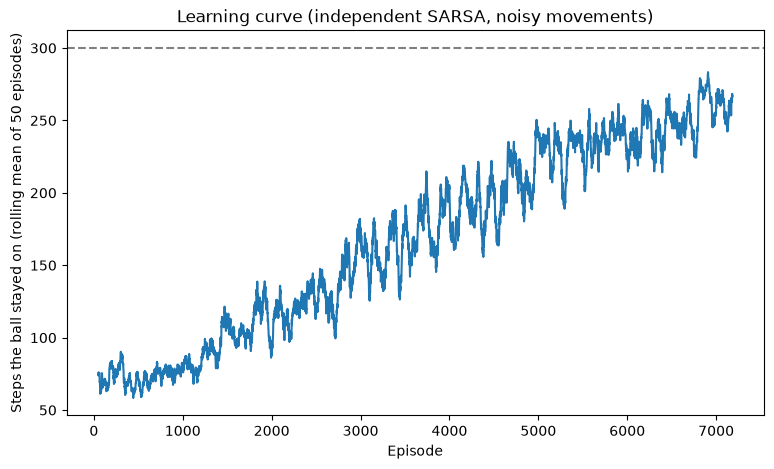

Ball stays on for 300 steps (last 200 episodes): 0.76
Share of time a side is at neutral:              0.37


In [15]:

df = pd.DataFrame(trained_model.episode_log)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(df["episode"], df["episode_length"].rolling(50).mean())
ax.axhline(300, color="grey", linestyle="--")
ax.set_xlabel("Episode")
ax.set_ylabel("Steps the ball stayed on (rolling mean of 50 episodes)")
ax.set_title("Learning curve (independent SARSA, noisy movements)")
plt.show()

print(f"Ball stays on for 300 steps (last 200 episodes): {trained_model.recent_success_rate:.2f}")
print(f"Share of time a side is at neutral:              {trained_model.neutral_share:.2f}")

# Make a custom visualization so we can watch the board in 3D
We draw the **actual** (noisy) tilt. Press play, not reset. Exploration is set low.

In [18]:
@solara.component
def BoardVisualization(model):
    from mesa.visualization.components.matplotlib_components import update_counter
    update_counter.get()
    fig = plt.Figure(figsize=(6, 5))
    # computed_zorder=False: we decide ourselves what is drawn on top (board below, ball on top).
    # Otherwise matplotlib sometimes draws the board over the ball, so the ball seems to be under it
    ax = fig.add_subplot(projection="3d", computed_zorder=False)
    h, r = model.actual_height, model.actual_rotation
    slope_x = 0.15 * (h["right"] - h["left"])   # left/right tilt from the heights
    slope_y = 0.15 * (r["left"] + r["right"])   # forward/backward tilt from the rotations
    lift = 0.15 * (h["left"] + h["right"])      # both up = the board just moves up
    # the board: a disc
    radius, angle = np.meshgrid(np.linspace(0, 1, 10), np.linspace(0, 2 * np.pi, 40))
    X, Y = radius * np.cos(angle), radius * np.sin(angle)
    ax.plot_surface(X, Y, lift + slope_x * X + slope_y * Y, color="burlywood", alpha=0.7, zorder=1)
    # the handles
    for sx in [-1, 1]:
        ax.scatter(sx, 0, lift + slope_x * sx, s=150, c="black", marker="s", zorder=5)
    # the ball (drawn last and on top, slightly above the board surface)
    b = model.ball
    ax.scatter(b.x, b.y, lift + slope_x * b.x + slope_y * b.y + 0.08, s=200, c="tab:red", zorder=10)
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_zlim(-0.8, 0.8)
    ax.set_xlabel("x (left - right)")
    ax.set_ylabel("y (back - front)")
    ax.set_title(f"episode {model.episode}, step {model.t}")
    solara.FigureMatplotlib(fig)

# lets freeze the learners now, so we can watch them act without learning anymore
for handler in trained_model.handlers:
    handler.epsilon = 0.05      # explore a little less, so we mostly see what they learned
    handler.learning = False    # freeze: they keep acting, but stop updating their Q-tables

page = SolaraViz(trained_model, components=[BoardVisualization], name="Board balancing with noisy movements")
page

Cannot show ipywidgets in text

# Do the two sides coordinate?
We look at what the two sides **want** (their intentions, before the motor noise), and correlate the left side with the right side over the last 5,000 steps.

* **Height:** the board tilts left/right by the *difference* between the two heights. So to tilt the board, one side has to go up while the other goes down. If the sides coordinate, we expect a **negative** correlation (anti-phase).
* **Rotation:** the board tilts forward/backward by the *sum* of the two rotations. So both sides have to rotate the same way. If the sides coordinate, we expect a **positive** correlation (in phase). A negative correlation would mean they twist the board, which does nothing to the ball.

Note that the agents cannot see each other. Each agent only reacts to the ball. So if we find coordination, it does not come from the agents responding to each other, but from both responding to the same ball. 

What things woudl make it so that we cant expect a lot of coordination?

  0%|          | 0/4 [00:00<?, ?it/s]

signal_noise                                         0.0   0.6
measure                                                       
left height ~ right height (expected negative)     -0.04 -0.01
left rotation ~ right rotation (expected positive)  0.10  0.05


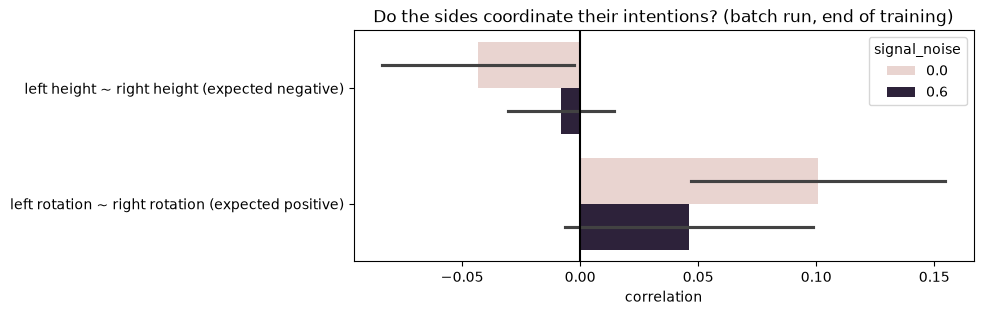

In [ ]:
# 1. the batch run
# we compare noise that does NOT grow with movement size (0.0) with noise that does (0.6)
params = {"signal_noise": [0.0, 0.6]}

results = mesa.batch_run(
    BoardModel,
    parameters=params,
    iterations=2,                # two runs per setting
    max_steps=600000,
    number_processes=1,
    data_collection_period=-1,   # only collect at the end of each run
    display_progress=True,
)
results = pd.DataFrame(results)
results.to_csv("./board_noise_batch_run.csv")

# 2. do the sides coordinate their intentions?
coord_cols = {"coord_height": "left height ~ right height (expected negative)",
              "coord_rotation": "left rotation ~ right rotation (expected positive)"}

# from wide (one column per correlation) to long (one row per run per correlation), for plotting
coordination = results.melt(id_vars=["signal_noise", "RunId"], value_vars=list(coord_cols),
                            var_name="measure", value_name="correlation")
coordination["measure"] = coordination["measure"].map(coord_cols)

# the average per noise setting, as a table
print(coordination.groupby(["measure", "signal_noise"])["correlation"].mean().unstack().round(2))

# and as a plot: one bar per noise setting, the black lines show the spread over runs
plt.figure(figsize=(8, 3))
sns.barplot(coordination, y="measure", x="correlation", hue="signal_noise", orient="h")
plt.axvline(0, color="black")
plt.title("Do the sides coordinate their intentions? (batch run, end of training)")
plt.xlabel("correlation")
plt.ylabel("")
plt.show()

# Experiments for you
1. **Anti-phase and in-phase.** Look at the coordination plot. Nobody told the agents that height needs anti-phase and rotation needs in-phase. Where does it come from? Why are the correlations far from -1 and +1?
2. **Big movements are expensive.** Compare `signal_noise=0` and a high value (e.g., 1.0). Do the agents learn to make smaller movements (more neutral) when big movements are noisy?
3. **Who does what?** Maybe one side does most of the left/right tilting, and the other side most of the forward/backward tilting. How would you check this? (Hint: look at `model.history`.)
4. **pair handlers that never trained together** If there are different roles emerging from this, we could pair agents together who have never interacted.
5. **Central learning.** Train with `setup="central"` (one learner with 81 joint actions). How does that compare? Think about the size of its Q-table: 2,401 states x 81 actions.
6. **More detail.** We now use 7 bins per dimension. Try 5 bins (fewer states) by removing bin edges in `observe()`. Does learning get faster? Does balancing get better or worse?
7. **No base noise.** Set `base_noise=0`. Now, doing nothing is perfectly precise. What do the agents learn? Is that realistic?